# Workshop 2 — FIR DELAY EFFECT
 - **Student:** Francesc SERRA CRESPÍ
 - **Email:** francesc.serra-crespi@universite-paris-saclay.fr
 - **Master Program:** M2 AI

In [1]:
import scipy.io.wavfile as wav
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import copy
from numpy.fft import fft, fftfreq, ifft
from scipy.fft import fftshift
from scipy.signal import fftconvolve

# 1. Fundamental Elements

## 1.1 Signal representation

We developed a signal_data class to simplify the manipulation and analysis of audio signals. The class stores the main properties of the signal, including the sampling rate, number of samples, duration, time vector, Nyquist frequency, and frequency resolution.

For a discrete signal containing (N) samples and sampled at a frequency (f_s), the main quantities are defined as:

$$
\Delta t = \frac{1}{f_s}
\qquad
T = \frac{N}{f_s}
\qquad
f_{\max} = \frac{f_s}{2}
\qquad
\Delta f = \frac{f_s}{N}
$$

where ($Delta$) is the sampling interval, ($T$) is the signal duration, ($f_{\max}$) is the Nyquist frequency, and ($\Delta f$) is the frequency resolution.

In [2]:
class signal_data: # Class to store signal data
    def __init__(self, filename):
        self.filename = filename
        self.rate, self.data = wav.read(filename)
        self.increment = 1 / self.rate
        self.length = len(self.data)
        self.duration = self.length / self.rate
        self.time = np.arange(0, self.length) / self.rate
        self.freq_max = self.rate / 2
        self.resolution_freq = self.rate / self.length


## 1.2 Unit impulse

We also defined a discrete unit impulse signal. It is represented as an array of ($N$) samples in which the first sample is equal to 1 and all the remaining samples are equal to 0:

$$
\delta[n] =
\begin{cases}
1, & n=0\\

0, & n\neq0
\end{cases}
$$

The unit impulse is particularly important because it allows us to obtain the impulse response of a system $h[n]$ for the $FIR$ filter a linear time-invariant system.

In [3]:
class delta_signal: # Class to store delta signal data
    def __init__(self, length):
        self.length = length
        self.data = np.zeros(length)
        self.data[0] = 1

## 1.3 FIR filter

The $FIR$ filter was implemented as a function that receives the input signal together with two parameters: the gain $\alpha$ and the delay $(D)$.

The filter adds a delayed and scaled copy of the original signal to the original signal itself. Its difference equation is:

$$
y[n] = x[n] + \alpha x[n-D]
$$

where $x[n]$ is the input signal, $y[n]$ is the filtered output, $(D)$ is the delay expressed in samples, and $\alpha$ controls the amplitude of the delayed copy.


In [4]:
def FIR_filter(signal_data, alpha, delay=1):
    # FIR filter implementation using zero padding because the sound signal
    # is finite and not periodic

    filtered_signal = np.zeros(signal_data.length)

    for n in range(signal_data.length):
        if n < delay:
            filtered_signal[n] = signal_data.data[n]
        else:
            filtered_signal[n] = signal_data.data[n] + alpha * signal_data.data[n-delay]

    return filtered_signal

# 2. Download of the audio and initial visulalization in time domain not in sampling doamin

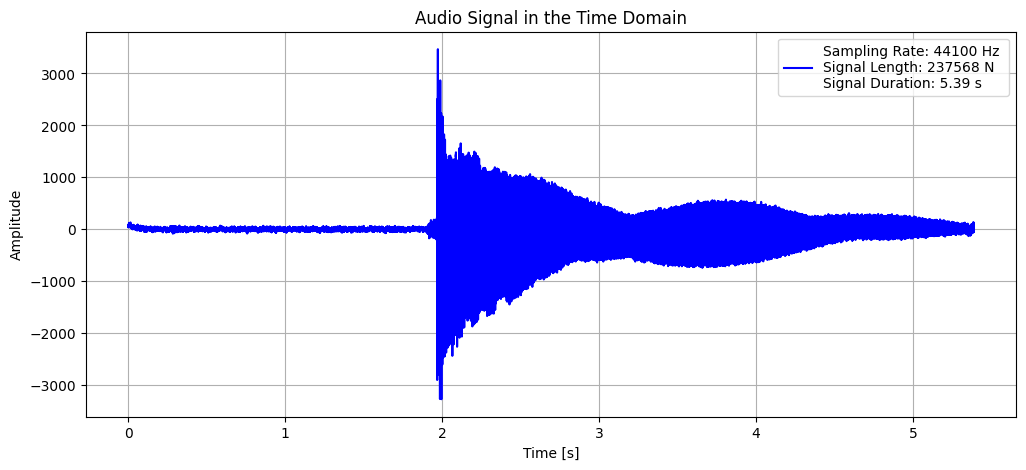

In [5]:
audio_signal = signal_data('data/string_1.wav')


plt.figure(figsize=(12, 5))
sns.lineplot(x=audio_signal.time, y=audio_signal.data,
    label=(
        f"Sampling Rate: {audio_signal.rate} Hz \n"
        f"Signal Length: {audio_signal.length} N\n"
        f"Signal Duration: {audio_signal.duration:.2f} s"),
    color='blue')

plt.title('Audio Signal in the Time Domain')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid()


# 3. FIR Filter Design and Signal Filtering

In [6]:
# FIR filter parameters
delay_samples = 10000  # Delay in samples
alpha_value = 0.8  # Feedback coefficient

print(f"Applying FIR filter with delay of {delay_samples} samples ({delay_samples * audio_signal.increment:.2f} seconds) and alpha value of {alpha_value}.")

Applying FIR filter with delay of 10000 samples (0.23 seconds) and alpha value of 0.8.


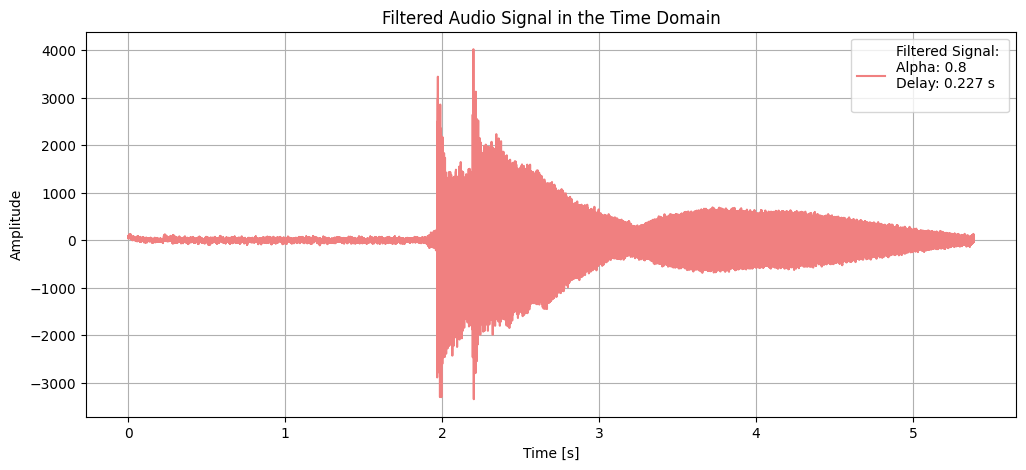

In [7]:

filtered_signal_data = FIR_filter(
    audio_signal,
    alpha=alpha_value,
    delay=delay_samples
)

seconds_delay= delay_samples * audio_signal.increment

# Plot 1 - Filtered signal
plt.figure(figsize=(12, 5))
sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    label=(
        'Filtered Signal: \n'
        f'Alpha: {alpha_value} \n'
        f'Delay: {seconds_delay:.3f} s\n'),
    color='lightcoral'
)

plt.title('Filtered Audio Signal in the Time Domain')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid()


Original maximum peak: 3466.00 at 1.9725 s
Filtered maximum peak: 4023.60 at 2.1990 s
Peak time difference: 0.2265 s
Expected FIR delay: 0.2268 s


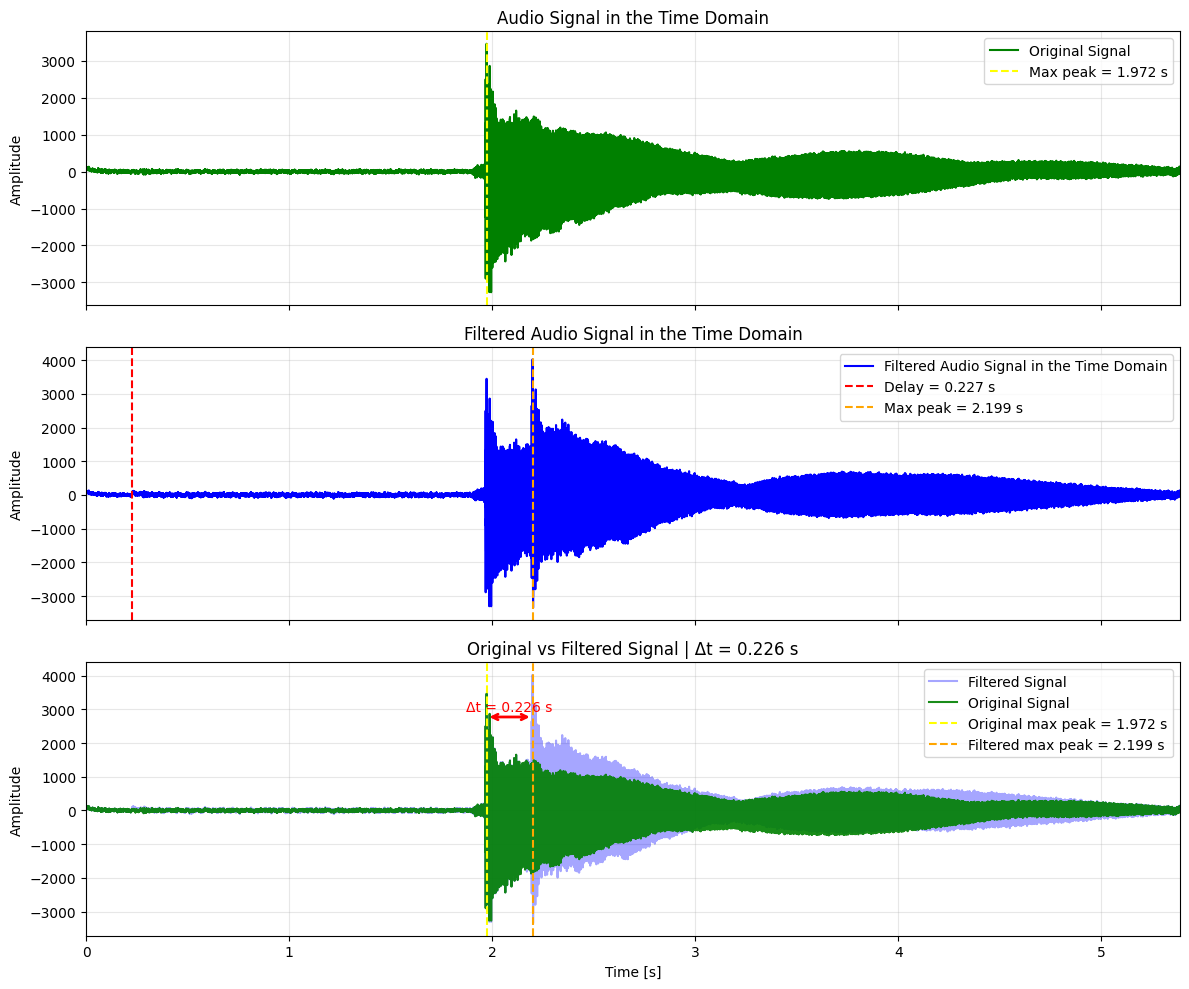

In [8]:
filtered_signal_data = FIR_filter(
    audio_signal,
    alpha=alpha_value,
    delay=delay_samples
)

seconds_delay= delay_samples * audio_signal.increment

# Maximum peak of original signal
max_peak_original_idx = np.argmax(np.abs(audio_signal.data))
max_peak_original_time = audio_signal.time[max_peak_original_idx]
max_peak_original_value = audio_signal.data[max_peak_original_idx]



# Maximum peak of filtered signal
max_peak_filtered_idx = np.argmax(np.abs(filtered_signal_data))
max_peak_filtered_time = audio_signal.time[max_peak_filtered_idx]
max_peak_filtered_value = filtered_signal_data[max_peak_filtered_idx]


# Difference between peaks
peak_delay = abs( max_peak_filtered_time - max_peak_original_time)

print(f"Original maximum peak: {max_peak_original_value:.2f} at {max_peak_original_time:.4f} s")
print(f"Filtered maximum peak: {max_peak_filtered_value:.2f} at {max_peak_filtered_time:.4f} s")
print(f"Peak time difference: {peak_delay:.4f} s")
print(f"Expected FIR delay: {seconds_delay:.4f} s")

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Plot 0 - Original signal
sns.lineplot( x=audio_signal.time, y=audio_signal.data,
    ax=axes[0],
    label='Original Signal',
    color='green')

axes[0].axvline( x=max_peak_original_time,
    color='yellow',
    linestyle='--',
    label=f'Max peak = {max_peak_original_time:.3f} s')

axes[0].set_title('Audio Signal in the Time Domain')
axes[0].set_ylabel('Amplitude')
axes[0].grid(alpha=0.3)
axes[0].legend()


# Plot 1 - Filtered signal
sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    ax=axes[1],
    label='Filtered Audio Signal in the Time Domain',
    color='b')

axes[1].axvline(
    x=seconds_delay,
    color='red',
    linestyle='--',
    label=f'Delay = {seconds_delay:.3f} s')

axes[1].axvline(
    x=max_peak_filtered_time,
    color='orange',
    linestyle='--',
    label=f'Max peak = {max_peak_filtered_time:.3f} s')

axes[1].set_title('Filtered Audio Signal in the Time Domain')
axes[1].set_ylabel('Amplitude')
axes[1].grid(alpha=0.3)
axes[1].legend()


# Plot 2 - Original + filtered

sns.lineplot( x=audio_signal.time, y=filtered_signal_data,
    ax=axes[2],
    label='Filtered Signal',
    color='blue',
    alpha=0.35)

sns.lineplot( x=audio_signal.time, y=audio_signal.data,
    ax=axes[2],
    label='Original Signal',
    color='green',
    alpha=0.9)


axes[2].axvline( x=max_peak_original_time,
    color='yellow',
    linestyle='--',
    label=f'Original max peak = {max_peak_original_time:.3f} s')

axes[2].axvline( x=max_peak_filtered_time,
    color='orange',
    linestyle='--',
    label=f'Filtered max peak = {max_peak_filtered_time:.3f} s')

y_position = np.max(np.abs(audio_signal.data)) * 0.8

axes[2].annotate(
    '',
    xy=(max_peak_filtered_time, y_position),
    xytext=(max_peak_original_time, y_position),
    arrowprops=dict(
        arrowstyle='<->',
        color='red',
        linewidth=2
    )
)

axes[2].text(
    (max_peak_original_time + max_peak_filtered_time) / 2,
    y_position+80,
    f'Δt = {peak_delay:.3f} s',
    color='red',
    ha='center',
    va='bottom'
)

axes[2].set_title(
    f'Original vs Filtered Signal | Δt = {peak_delay:.3f} s'
)

axes[2].set_xlabel('Time [s]')
axes[2].set_ylabel('Amplitude')
axes[2].set_xlim(0, audio_signal.duration)
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

## Insight
![FIR filter operation](FIR_filter.png)
> As illustrated in the previous figure describing the FIR filter operation, the system output is obtained by adding the original signal $x[n]$ to a delayed and scaled copy $\alpha x[n-D]$.
>
> The time-domain results shown here confirm this behaviour. The maximum peak of the original signal appears at approximately **1.972 s**, while the filtered signal reaches another maximum peak at approximately **2.199 s**. Therefore, the measured difference is:
>
> $$\Delta t \approx 2.199-1.972=0.226\text{ s}$$
>
> This value is almost identical to the theoretical delay of **0.227 s** introduced by the filter. Therefore, the second peak observed in the filtered signal corresponds to the delayed component represented in the previous schematic.
>
> Since this delayed copy is added only once, without feedback, the response does not repeat indefinitely. This behaviour is also consistent with the impulse response obtained in the next section, which contains only two non-zero components: one at $n=0$ and another at $n=D$ with amplitude $\alpha$. This confirms the **finite nature of the FIR filter**.

# 4. Impulse Response
The impulse response $h[n]$ represents the output of the filter when a discrete Dirac delta $\delta[n]$ is applied as the input signal.


Text(0, 0.5, 'Impulse Response h[n]')

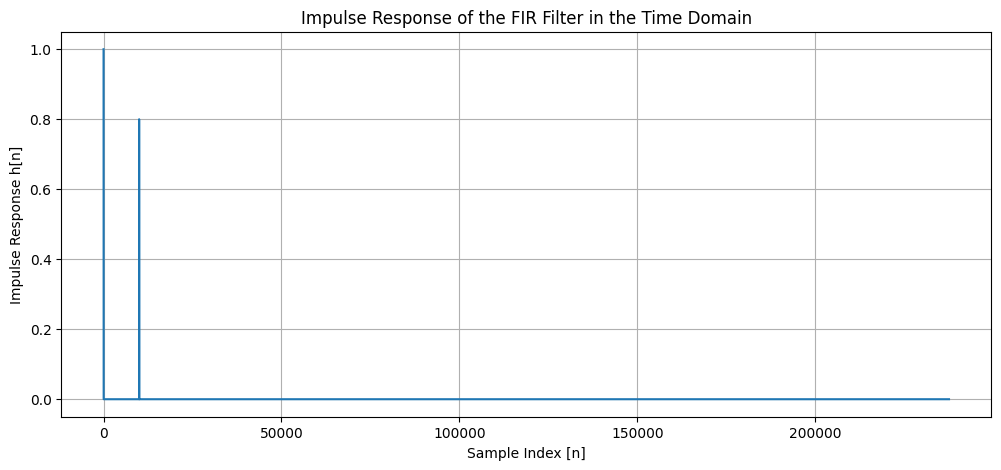

In [9]:
N = len(audio_signal.data)
delta = delta_signal(N)

impulse_response = FIR_filter(delta, alpha=alpha_value, delay=delay_samples)

plt.figure(figsize=(12, 5))
sns.lineplot(x=range(N), y=impulse_response)
plt.grid()
plt.title('Impulse Response of the FIR Filter in the Time Domain')
plt.xlabel('Sample Index [n]')
plt.ylabel('Impulse Response h[n]')

## Insight

> The impulse response shows directly how the FIR filter operates. The first impulse at $n=0$ represents the original signal, while the second impulse at $n=10000$, with an amplitude of $0.8$, represents a delayed and scaled copy of the original signal.
>
> Therefore, before the delay, the output only contains the original signal. From $n=10000$ onwards, the delayed copy is added to the original signal:
>
> $$
> y[n]=x[n]+0.8x[n-10000]
> $$
>
> As illustrated in the previous diagram of the filter operation, the delayed signal is added only once and does not repeat over time. This is reflected in the impulse response by the presence of only two non-zero impulses, confirming the finite nature of the FIR filter.

## Stability Insight

> The FIR filter is stable because its response is finite. The delayed signal is added only once, so its effect does not keep repeating or growing over time.
>
> This is different from an IIR filter, where the output is fed back into the system. A simple IIR filter can be written as:
>
> $$
> y[n]=\alpha x[n]+\beta y[n-D]
> $$
>
> The term $\beta y[n-D]$ introduces feedback, meaning that previous output values are repeatedly reintroduced into the system. For this filter, stability requires:
>
> $$
> |\beta|<1
> $$
>
> If $|\beta|>1$, each repeated contribution becomes larger than the previous one, causing the response to grow without bound. Therefore, unlike the FIR filter, an IIR filter can become unstable depending on the value of the feedback coefficient $\beta$.

# 5. FIR Filter Analysis in the Frequency Domain

Once the impulse response $h[n]$ is obtained, its Fourier Transform gives us the **frequency response of the filter**, $H(f)$. This allows us to understand how the filter affects the different frequency components of the input signal.

Another important advantage of the frequency domain is that filtering can be performed using a simple element-wise multiplication, however in the time domain, the output is obtained through convolution.

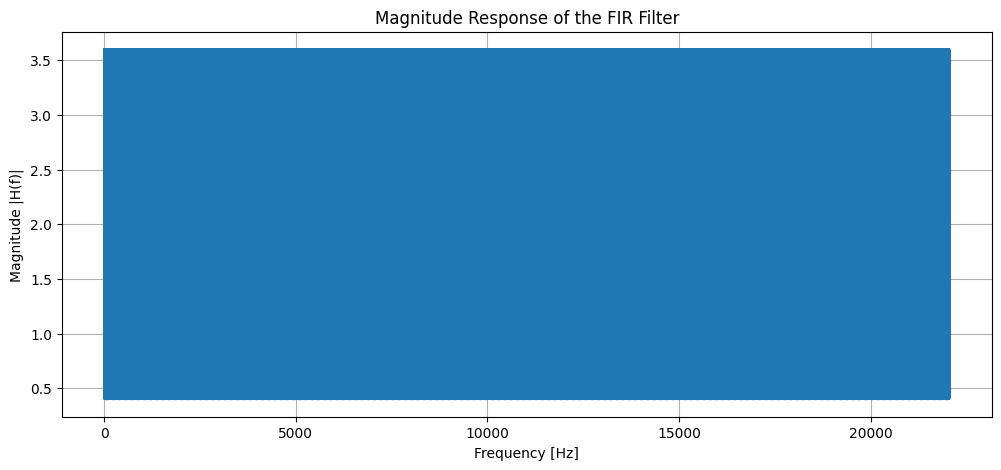

In [10]:
# 1. Discrete Fourier Transform (DFT)
fft_impulse = fft(impulse_response)
freqs_impulse = fftfreq(len(impulse_response), d=1/audio_signal.rate)

# Centered version (zero in the middle), for a symmetric plot
sig_s1_shift = fftshift(fft_impulse)
f_s1_shift = fftshift(freqs_impulse)
mag_shift = np.abs(sig_s1_shift)

# One-sided version: positive frequencies only
mitad = len(impulse_response) // 2
f_pos = freqs_impulse[:mitad]
mag_pos = 2 * np.abs(fft_impulse[:mitad])

# Plot frequency response
plt.figure(figsize=(12, 5))
sns.lineplot(x=f_pos, y=mag_pos)
plt.title('Magnitude Response of the FIR Filter')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude |H(f)|')
plt.grid()


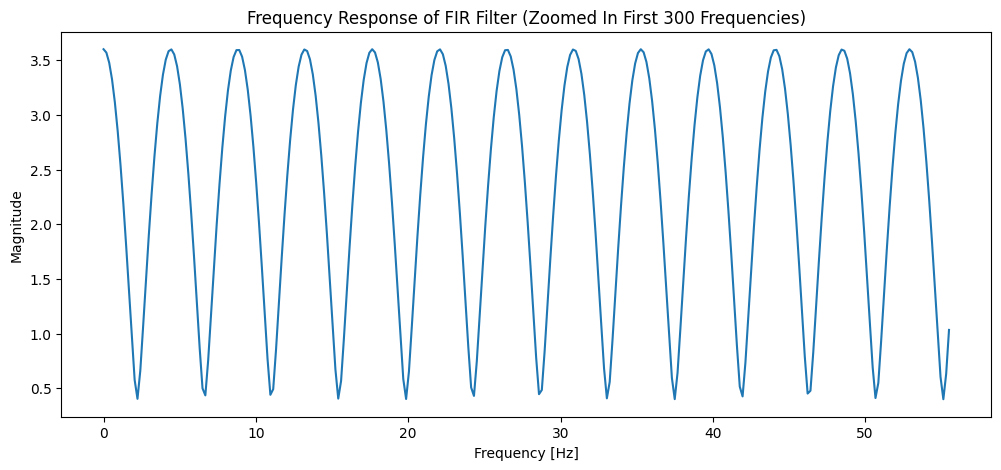

In [11]:
plt.figure(figsize=(12, 5))
sns.lineplot(x=f_pos[0:300], y=mag_pos[0:300])
plt.title('Frequency Response of FIR Filter (Zoomed In First 300 Frequencies)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.show()

## Frequency Response Insight

> The frequency response is periodic and does not behave like a typical low-pass, high-pass, band-pass, or band-stop filter.
>
> However, it is useful for the next section, where we compare filtering in the time domain using convolution with filtering in the frequency domain using point-wise multiplication, including the required zero-padding to obtain a linear convolution.

# 6. Time-Domain Convolution vs. Frequency-Domain Pointwise Multiplication

The filtered signal can be obtained in the time domain by convolving the original audio signal with the impulse response of the FIR filter:

$$
y[n]=x[n]*h[n]
$$

In the frequency domain, this operation is equivalent to multiplying the Fourier transforms of both signals point by point:

$$
Y(f)=X(f)\cdot H(f)
$$

Therefore, we can compare both approaches and verify that they produce the same filtered signal.

Since filtering an LTI system requires **linear convolution**, special care must be taken when using the FFT. Direct multiplication of two DFTs corresponds to circular convolution, so zero-padding is required to obtain the same result as linear convolution.

For signals of lengths $L_1$ and $L_2$, the minimum required FFT length is:

$$
L=L_1+L_2-1
$$


## 6.1 Time-Domain Convolution

Length of convolution result: 237568
Length of filtered signal: 237568


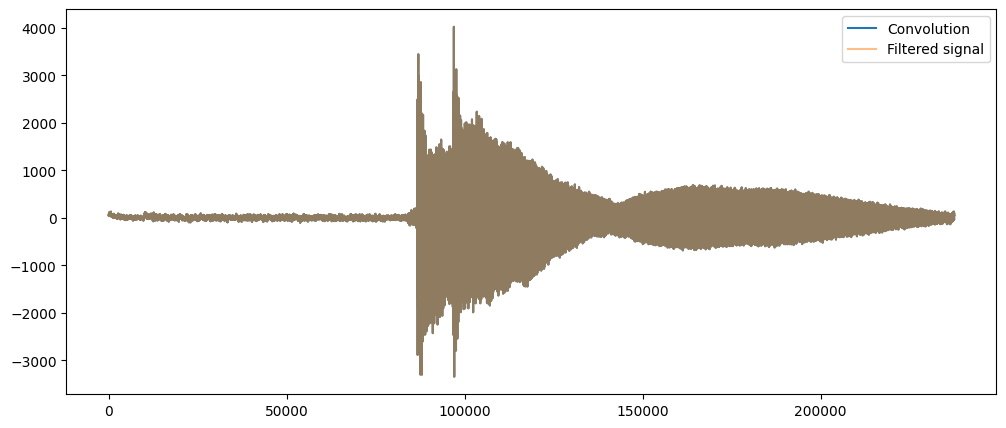

Is the filtered signal equal to the convolution? True


In [12]:
# Full convolution
conv_full = fftconvolve(
    audio_signal.data,
    impulse_response,
    mode="full" # we have used full to be able to obtain a linear convolution with the requirement of Lx + Lh - 1
)

# Keep the causal part corresponding to the original signal
conv_signal = conv_full[:len(audio_signal.data)]

print(f'Length of convolution result: {len(conv_signal)}')
print(f'Length of filtered signal: {len(filtered_signal_data)}')

plt.figure(figsize=(12, 5))
plt.plot(conv_signal, label="Convolution")
plt.plot(filtered_signal_data, label="Filtered signal", alpha=0.5)
plt.legend()
plt.show()
print(f'Is the filtered signal equal to the convolution? {np.allclose(conv_signal, filtered_signal_data)}')

## Frequency-Domain Pointwise Multiplication

Length of original signal: 237568
Length of impulse response: 237568
Length required for linear convolution: 475135
Length of padded signal: 475135
Length of padded impulse response: 475135


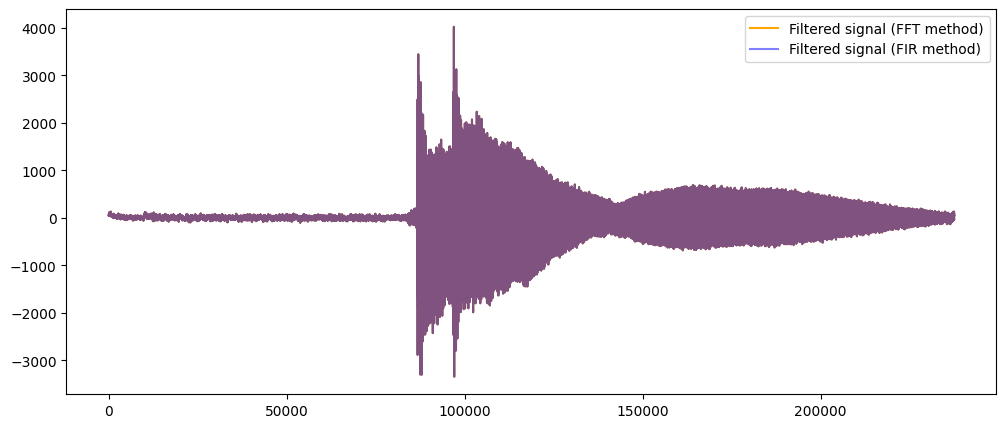

Is the filtered signal equal to the filtered signal using the FFT method? True


In [13]:
# Length required for linear convolution
print(f"Length of original signal: {len(audio_signal.data)}")
print(f"Length of impulse response: {len(impulse_response)}")

N = 2 * audio_signal.length - 1
print(f"Length required for linear convolution: {N}")

# Amount of zero-padding needed
N_padding = N - len(audio_signal.data)

# Zero-padding
audio_signal_padded = np.pad(
    audio_signal.data,
    (0, N_padding),
    mode='constant'
)

impulse_response_padded = np.pad(
    impulse_response,
    (0, N_padding),
    mode='constant'
)

print(f"Length of padded signal: {len(audio_signal_padded)}")
print(f"Length of padded impulse response: {len(impulse_response_padded)}")

# FFT
audio_signal_fft = fft(audio_signal_padded)
impulse_response_fft = fft(impulse_response_padded)

# Multiplication in frequency domain
audio_signal_filtered_fft = (
    audio_signal_fft * impulse_response_fft
)

# Back to time domain
audio_signal_filtered_fftmethod = np.real(
    ifft(audio_signal_filtered_fft)
)[0:len(audio_signal.data)]  # Keep only the causal part corresponding to the original signal

# Compare
plt.figure(figsize=(12, 5))

plt.plot(
    audio_signal_filtered_fftmethod,
    label="Filtered signal (FFT method)",
    color='orange'
)

plt.plot(
    filtered_signal_data,
    label="Filtered signal (FIR method)",
    alpha=0.5,
    color='blue'
)

plt.legend()
plt.show()

print(f'Is the filtered signal equal to the filtered signal using the FFT method? {np.allclose(audio_signal_filtered_fftmethod, filtered_signal_data)}')

## Insights

> The results show that the three approaches are mathematically equivalent:
>
> $$
> \text{FIR filtering}
> \;\Longleftrightarrow\;
> \text{Time-domain convolution}
> \;\Longleftrightarrow\;
> \text{Frequency-domain pointwise multiplication}
> $$
>
> This equivalence is confirmed in two ways. First, the plots show that the resulting signals overlap almost perfectly. Second, a sample-by-sample comparison shows that the numerical values obtained with the three methods are the same, apart from possible small numerical errors due to floating-point precision.
>
> However, the complete linear convolution is longer than the original audio signal. Since the direct FIR implementation returns an output with the same length as the input, we keep only the first $N$ samples:
>
>
> This makes all three signals have the same length and allows both a visual and a sample-by-sample comparison.